K-fold validation

Tests whether the k-fold scoring used in `Task_2_corrected.ipynb` does its three jobs:

1. **Removes overtraining bias** - compare the k-fold (out-of-fold) scores with what you would get from one model scoring the events it was trained on.
2. **Gives correct efficiencies** (closure test) - run the k-fold on 80% of the simulation and check that its out-of-fold efficiencies match those on the untouched 20%, scored the way real data is (one randomly chosen fold model per event; the 5-model average is shown too).
3. **Is stable** - how much the 5 fold models differ from each other, and how often an event's selection depends on which model scores it.

Optional: whether the 1-SE tree rule is worth it (the nested k-fold re-tuned for the minimum-loss tree count).

The setup cells are copies of `Task_2_corrected.ipynb`'s (loading with the engineered features, preselection, features, labels). The k-fold function reproduces its nested k-fold exactly (Optuna inside every fold, 1-SE tree count in the objective). If any of these change there, change them here too. Needs `optuna_kfold_params.json`, written by Task_2_corrected's k-fold cell with `RUN_OPTUNA = True`: the main k-fold re-uses those per-fold settings, while Job 2 and the optional test each run their own 5 × 40-trial search.

Setup (copied from Task_2_corrected)

In [1]:
# ---------------------------------------------------------------------------------------------
# DATA SOURCES (all in MicroBooNE_data/, one pandas DataFrame per file, one row per candidate track):
#   Simulation.pkl            simulated events with NO oscillation. Has reconstructed variables (what the
#                             detector measures) AND truth columns ("Simulation ..."): true category, true
#                             neutrino energy, and a weight saying how many real events each row represents.
#                             Used to train the BDT and to build every prediction.
#   Data.pkl                  real MicroBooNE events. Reconstructed variables only - no truth, no weights
#                             (each row counts as one real event). Used only for the final fit (Task 6).
#   OscillatedSimulation.pkl  exactly the same events as Simulation.pkl, in the same order, but with weights
#                             multiplied by an oscillation probability for some chosen (Δm², sin²2θ).
#                             Used as fake data with a known answer (Task 5).
# Each event can appear as several rows ("Subevent"s = candidate tracks); the preselection keeps one.
# ---------------------------------------------------------------------------------------------
import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import xgboost
from sklearn.model_selection import StratifiedGroupKFold, GroupShuffleSplit
from sklearn.metrics import roc_curve, roc_auc_score, log_loss

# Figure style for presentations: large text, thick lines and big markers, so every figure stays readable when
# pasted onto a slide at its notebook size. Individual plots only set sizes where they need something different.
plt.rcParams.update({
    "figure.figsize": (8, 5.5),
    "font.size": 15, "axes.titlesize": 17, "axes.labelsize": 17, "figure.titlesize": 18,
    "xtick.labelsize": 15, "ytick.labelsize": 15, "legend.fontsize": 14, "legend.title_fontsize": 14,
    "lines.linewidth": 2.5, "lines.markersize": 7,
    "axes.linewidth": 1.2, "xtick.major.width": 1.2, "ytick.major.width": 1.2,
    "xtick.major.size": 6, "ytick.major.size": 6,
    "savefig.dpi": 200, "savefig.bbox": "tight",
})

TOPO = "Topological muon ML score"                                          # same on every row of an event
VERTEX = [f"Interaction vertex position {a} component" for a in "xyz"]     # same on every row of an event
START = [f"Start position of lepton track {a} component" for a in "xyz"]
END = [f"End position of lepton track {a} component" for a in "xyz"]
LENGTH = "Length of lepton track"
P_RANGE = "Muon momentum (length estimate)"
P_MCS = "Muon momentum (scattering estimate)"

# MicroBooNE TPC active volume in cm (a few reconstructed points lie slightly outside)
TPC = [(0.0, 256.35), (-116.5, 116.5), (0.0, 1036.8)]   # x, y, z

# Engineered features chosen in Feature_study.ipynb (direction, event context, containment)
ENGINEERED = ["cos_beam", "cos_vert", "n_tracks", "min_end_wall", "start_wall_dist"]

def wall_dist(points):
    """Signed distance (cm) from each point to the nearest TPC face; negative if the point is outside."""
    return np.min([np.minimum(points[:, i] - lo, hi - points[:, i]) for i, (lo, hi) in enumerate(TPC)], axis=0)

def add_features(df):
    """Add the engineered features to every row, from reconstructed quantities only (so it works for
    simulation, data and the oscillated set alike). Runs before preselection, because n_tracks needs
    all of an event's rows."""
    v = df[VERTEX].to_numpy(dtype=float)
    start = df[START].to_numpy(dtype=float)
    end = df[END].to_numpy(dtype=float)

    # Direction of the track, pointing away from the vertex (from the nearer track end to the farther one)
    flipped = np.linalg.norm(end - v, axis=1) < np.linalg.norm(start - v, axis=1)
    near = np.where(flipped[:, None], end, start)
    far = np.where(flipped[:, None], start, end)
    seg = far - near
    seg_len = np.linalg.norm(seg, axis=1)
    seg_len = np.where(seg_len > 0, seg_len, np.nan)
    df["cos_beam"] = seg[:, 2] / seg_len     # +1 = along the beam (z): neutrino muons are boosted forward
    df["cos_vert"] = seg[:, 1] / seg_len     # +1 = straight up, -1 = straight down: cosmics are near-vertical

    # Containment: how close the track's ends are to the detector boundary
    df["start_wall_dist"] = wall_dist(start)
    df["min_end_wall"] = np.minimum(df["start_wall_dist"], wall_dist(end))

    # Event context: number of candidate tracks (rows) in the event
    df["n_tracks"] = df.groupby("event_id")[LENGTH].transform("size")
    return df

def load(name):
    """Load one of the pickles, fix its column types, and label which rows belong to the same event."""
    df = pd.read_pickle(f"MicroBooNE_data/{name}")
    # 12 numeric columns are stored with the generic 'object' type; convert them so they can be used as numbers
    obj_cols = df.columns[df.dtypes == object]
    df[obj_cols] = df[obj_cols].astype("float32")   # numeric columns stored as generic objects
    # Rows of one event share the topological score and vertex; a new event starts when either changes.
    # The vertex is needed too, because ~17k rows have a score of exactly 0 and would merge with neighbours.
    key = df[[TOPO] + VERTEX].round(6)
    # (key != key.shift()) is True on the first row of each new event; the running total numbers the events
    df["event_id"] = (key != key.shift()).any(axis=1).cumsum()
    return add_features(df)

sim = load("Simulation.pkl")   # all simulated candidate rows (~556k rows, ~398k events), before any selection

# Column names used throughout
CAT = "Simulation category"     # true event type (simulation only): 21 = numu CC signal, 31 = NC, 10 = nue CC,
                                # 7 = EXT (beam off), 5 = outside fiducial volume, 4 = cosmic mis-ID
WGT = "Simulation weight"       # how many real events each simulated row represents (simulation only)
ENERGY = "Total energy"         # reconstructed energy in GeV - the variable whose spectrum we fit
SIGNAL = 21                     # the category we want to select: muon-neutrino charged-current
PARAMS_FILE = "optuna_kfold_params.json"   # per-fold Optuna results (nested search), saved and loaded by the k-fold cell

In [2]:
# Split the columns into truth (only the simulation knows these), bookkeeping, and reconstructed
# variables (measured by the detector, so they also exist in real data). The BDT may only use the last group.
# The engineered features are kept separate here and added in the feature-selection cell below.
truth_cols = [c for c in sim.columns if c.lower().startswith("simulat")]   # category, weight, true energy, ...
id_cols = ["Subevent", "event_id"]                                          # row/event labels, not physics
reco_cols = [c for c in sim.columns
             if c not in truth_cols and c not in id_cols and c not in ENGINEERED
             and pd.api.types.is_numeric_dtype(sim[c])]
print(reco_cols)

['Distance to closest cosmic ray track', 'Length of lepton track', 'Distance to longest track', 'Topological muon ML score', 'End position of lepton track z component', 'End position of lepton track y component', 'End position of lepton track x component', 'Track vs shower ML score', 'Particle ID LLh', 'Start position of lepton track z component', 'Start position of lepton track y component', 'Start position of lepton track x component', 'Interaction vertex position x component', 'Interaction vertex position y component', 'Interaction vertex position z component', 'Total energy', 'Muon momentum (length estimate)', 'Muon momentum (scattering estimate)']


In [3]:
def preselect(df):
    """Applied identically to simulation, data and oscillated simulation."""
    # 1. Drop events with no usable energy: ~76% of events carry a placeholder of ~10,000 GeV instead of a
    #    measured energy (the flag is the same on every row of an event, so whole events are removed)
    df = df[df[ENERGY] < 100]   # ~10,000 GeV is a placeholder flag, not a measured energy
    # 2. Keep one candidate track per event: the row with the highest Particle ID log-likelihood (most muon-like)
    best = df.groupby("event_id")["Particle ID LLh"].idxmax()   # most muon-like track in each event
    # reset_index gives rows a clean 0..n-1 index, which later cells rely on
    return df.loc[best].reset_index(drop=True)

pre = preselect(sim)   # preselected simulation: one row per event; used for BDT training and all predictions

# Bookkeeping: how much survives the preselection
events = sim.drop_duplicates("event_id")   # truth and weight are the same on every row of an event
sig_all = events.loc[events[CAT] == SIGNAL, WGT].sum()   # weighted signal events before preselection
sig_pre = pre.loc[pre[CAT] == SIGNAL, WGT].sum()         # ... and after
print(f"Candidates: {len(sim)} -> {len(pre)} (one per event)")
print(f"Events kept: {len(pre) / len(events): .1%}")
print(f"Signal kept: {sig_pre / sig_all: .1%}")

Candidates: 555624 -> 95748 (one per event)
Events kept:  24.1%
Signal kept:  45.2%


In [4]:
# Which reconstructed variables the BDT is allowed to use (feature set chosen in Feature_study.ipynb).
# Total energy is left out by default: it is the variable we fit later, so letting the selection use it
# directly could shape the energy spectrum.
USE_ENERGY_VARS = False
energy_like = [ENERGY]
# Original features removed as redundant: the two muon momentum estimates (add nothing once the engineered
# features are in; the range estimate is a function of track length) and the raw track start position
# (the track starts at the vertex, so it duplicates the vertex position)
REMOVED = [P_RANGE, P_MCS] + START

features = [c for c in reco_cols if (USE_ENERGY_VARS or c not in energy_like) and c not in REMOVED] + ENGINEERED
print(len(features), "features:", features)

17 features: ['Distance to closest cosmic ray track', 'Length of lepton track', 'Distance to longest track', 'Topological muon ML score', 'End position of lepton track z component', 'End position of lepton track y component', 'End position of lepton track x component', 'Track vs shower ML score', 'Particle ID LLh', 'Interaction vertex position x component', 'Interaction vertex position y component', 'Interaction vertex position z component', 'cos_beam', 'cos_vert', 'n_tracks', 'min_end_wall', 'start_wall_dist']


In [5]:
# Inputs for the BDT, all built from the preselected simulation `pre` (one row per event)
pre["is_sig"] = (pre[CAT] == SIGNAL).astype(int) # 1 or 0 TRUTH column.   The answer the BDT learns: 1 = numu CC, 0 = anything else

X = pre[features].replace([np.inf, -np.inf], np.nan) # BDT doesn't handle infinities well.   Inputs: reconstructed variables only
y = pre["is_sig"]                                     # labels
w_fit = pre[WGT] / pre[WGT].mean() # rescaled to average 1.   Event weights, so the BDT learns the real beam's mix of events

In [6]:
# Per-fold hyperparameters from Task_2_corrected.ipynb's nested search (re-used by the main k-fold, which has the
# same folds and inner splits), and real data for the stability test
with open(PARAMS_FILE) as f:
    saved = json.load(f)
saved_fold_params = [fold["params"] for fold in saved["folds"]]
print(f"Loaded {PARAMS_FILE} (saved {saved['saved']}, {saved['n_trials_per_fold']} trials per fold, "
      f"SE_SCALE {saved['se_scale']})")
if saved["features"] != features:
    print("WARNING: these hyperparameters were tuned with a different feature list - re-run the search in Task_2_corrected")

data_pre = preselect(load("Data.pkl"))   # all preselected real events
names = {21: "numu CC (signal)", 31: "nu NC", 10: "nue CC", 7: "EXT (beam off)",
         5: "Out of fiducial vol.", 4: "Cosmic mis-ID"}
BKG = [4, 5, 7, 31]                       # backgrounds large enough to measure (nue CC has too few events)

Loaded optuna_best_params.json (saved 2026-10-26T02:31:36, 40 trials)


The nested k-fold, as in Task_2_corrected, plus the helpers every test uses

In [7]:
K = 5                  # number of folds
SPLIT_SEED = 1         # random_state of the fold split, as in Task_2_corrected
INNER_SPLITS = 5       # inner validation set = 1/INNER_SPLITS (20%) of each fold's training events
N_TRIALS = 40          # Optuna trials per fold (for the runs that tune: Job 2 and the optional test)
SE_SCALE = 1.0         # 1-SE tree rule, as in Task_2_corrected
EARLY_STOP = 50        # stop when the inner-validation loss hasn't improved for this many trees
N_BOOT = 200           # bootstrap resamples for uncertainties
y_all, w_all = y.to_numpy(), pre[WGT].to_numpy()
cat_all, E_all = pre[CAT].to_numpy(), pre[ENERGY].to_numpy()
groups_all = pre["event_id"]

# --- copied from Task_2_corrected's settings cell ---
def one_se_trees(model, X_v, y_v, w_v, scale=SE_SCALE):
    """Fewest trees whose inner-validation log loss is within `scale` standard errors of its minimum.
    Returns (tree count to use, minimum-loss tree count, standard error of the loss at the minimum)."""
    curve = np.array(model.evals_result_["validation_0"]["logloss"])
    best = curve.argmin()
    p = np.clip(model.predict_proba(X_v, iteration_range=(0, best + 1))[:, 1], 1e-15, 1 - 1e-15)
    yv, w = np.asarray(y_v), np.asarray(w_v)
    per_event = -(yv * np.log(p) + (1 - yv) * np.log(1 - p))   # each event's own log loss
    L = np.average(per_event, weights=w)
    se = np.sqrt(np.sum(w**2 * (per_event - L)**2)) / w.sum()  # standard error of a weighted mean
    return int(np.argmax(curve <= curve[best] + scale * se)) + 1, int(best) + 1, float(se)

def fit_1se(params, Xt, yt, wt, Xv, yv, wv, scale=SE_SCALE):
    """Train with early stopping on the inner-validation log loss, then choose the tree count with the 1-SE rule.
    Used inside every Optuna trial and for each fold's final model, so the two are built identically."""
    es = xgboost.XGBClassifier(**params, n_estimators=3000, early_stopping_rounds=EARLY_STOP,
                               eval_metric="logloss", tree_method="hist", n_jobs=-1, random_state=1)
    es.fit(Xt, yt, sample_weight=wt, eval_set=[(Xv, yv)], sample_weight_eval_set=[wv], verbose=False)
    n, best, se = one_se_trees(es, Xv, yv, wv, scale)
    return es, n, best, se

def tune_fold(Xt, yt, wt, Xv, yv, wv, seed, n_trials=N_TRIALS, scale=SE_SCALE):
    """Optuna (TPE Bayesian optimisation) on one fold's inner split. Returns the winning settings, their scores,
    every trial's score (for the history plot) and how much each hyperparameter mattered."""
    import optuna

    def objective(trial):
        params = {
            "colsample_bylevel": trial.suggest_float("colsample_bylevel", 0.5, 1.0),
            "colsample_bynode":  trial.suggest_float("colsample_bynode", 0.5, 1.0),
            "max_bin":           trial.suggest_int("max_bin", 64, 1024, log=True),
            "max_delta_step":    trial.suggest_float("max_delta_step", 0, 10),
            "grow_policy":       trial.suggest_categorical("grow_policy", ["depthwise", "lossguide"]),
            "max_leaves":        trial.suggest_int("max_leaves", 8, 256, log=True),
            "learning_rate":    trial.suggest_float("learning_rate", 0.01, 1, log=True),
            "max_depth":        trial.suggest_int("max_depth", 2, 10),
            "min_child_weight": trial.suggest_float("min_child_weight", 0.1, 20, log=True),  # min weight needed to make a split
            "subsample":        trial.suggest_float("subsample", 0.5, 1.0),                  # fraction of events used per tree
            "colsample_bytree": trial.suggest_float("colsample_bytree", 0.5, 1.0),           # fraction of features used per tree
            "gamma":            trial.suggest_float("gamma", 1e-3, 5, log=True),             # min loss improvement to split
            "reg_lambda":       trial.suggest_float("reg_lambda", 1e-3, 10, log=True),       # L2 penalty on leaf values
            "reg_alpha":        trial.suggest_float("reg_alpha", 1e-3, 10, log=True),        # L1 penalty on leaf values
        }
        es, n, best, se = fit_1se(params, Xt, yt, wt, Xv, yv, wv, scale)
        # Training AUC at the same tree count (the training-validation gap shows overfitting)
        trial.set_user_attr("train_auc", roc_auc_score(yt, es.predict_proba(Xt, iteration_range=(0, n))[:, 1],
                                                       sample_weight=wt))
        # The number Optuna maximises: weighted inner-validation AUC of the model that would actually be used
        return roc_auc_score(yv, es.predict_proba(Xv, iteration_range=(0, n))[:, 1], sample_weight=wv)

    optuna.logging.set_verbosity(optuna.logging.WARNING)
    study = optuna.create_study(direction="maximize", sampler=optuna.samplers.TPESampler(seed=seed))
    # No warm start from earlier results: those were tuned with every event visible, including this fold's
    # held-out events, so re-using them would bring back the leak the nested search removes
    study.optimize(objective, n_trials=n_trials, show_progress_bar=True)
    return {"params": study.best_params,
            "inner_val_auc": float(study.best_value),
            "train_auc": float(study.best_trial.user_attrs["train_auc"]),
            "history": [t.value for t in study.trials],
            "importance": dict(optuna.importance.get_param_importances(study))}
# --- end of copy ---

def run_kfold(rows, se_scale=SE_SCALE, fold_params=None, split_seed=SPLIT_SEED):
    """Nested k-fold on the events at positions `rows` of pre, exactly as in Task_2_corrected: Optuna inside every
    fold on an inner split (skipped if fold_params gives one settings dict per fold), early stopping + 1-SE tree
    count, then score the held-out fold. Returns a dict with the out-of-fold scores (aligned with rows), fold labels,
    models, settings, tree counts, per-fold losses, and which events each model fitted its trees on."""
    Xs, ys, ws, gs = X.iloc[rows], y.iloc[rows], w_fit.iloc[rows], groups_all.iloc[rows]
    oof, fold = np.full(len(rows), np.nan), np.full(len(rows), -1)
    out = {"models": [], "params": [], "trees": [], "best": [], "train loss": [], "held-out loss": [],
           "in_train": np.zeros((K, len(rows)), dtype=bool)}
    skf = StratifiedGroupKFold(n_splits=K, shuffle=True, random_state=split_seed)
    for k, (fit_idx, out_idx) in enumerate(skf.split(Xs, ys, gs)):
        inner = StratifiedGroupKFold(n_splits=INNER_SPLITS, shuffle=True, random_state=k)
        tr_rel, iv_rel = next(inner.split(fit_idx, ys.iloc[fit_idx], gs.iloc[fit_idx]))
        tr_idx, iv_idx = fit_idx[tr_rel], fit_idx[iv_rel]
        Xt, yt, wt = Xs.iloc[tr_idx], ys.iloc[tr_idx], ws.iloc[tr_idx]
        Xv, yv, wv = Xs.iloc[iv_idx], ys.iloc[iv_idx], ws.iloc[iv_idx]
        if fold_params is None:
            print(f"  fold {k}: tuning ({N_TRIALS} trials)")
            params_k = tune_fold(Xt, yt, wt, Xv, yv, wv, seed=k, scale=se_scale)["params"]
        else:
            params_k = fold_params[k]
        _, n_k, best_k, _ = fit_1se(params_k, Xt, yt, wt, Xv, yv, wv, se_scale)
        m = xgboost.XGBClassifier(**params_k, n_estimators=n_k, tree_method="hist", n_jobs=-1, random_state=1)
        m.fit(Xt, yt, sample_weight=wt)
        oof[out_idx] = m.predict_proba(Xs.iloc[out_idx])[:, 1]
        fold[out_idx] = k
        out["in_train"][k, tr_idx] = True
        out["models"].append(m); out["params"].append(params_k); out["trees"].append(n_k); out["best"].append(best_k)
        out["train loss"].append(log_loss(ys.iloc[fit_idx], m.predict_proba(Xs.iloc[fit_idx])[:, 1],
                                          sample_weight=ws.iloc[fit_idx]))
        out["held-out loss"].append(log_loss(ys.iloc[out_idx], oof[out_idx], sample_weight=ws.iloc[out_idx]))
        print(f"  fold {k}: best {best_k} trees -> using {n_k}")
    out["oof"], out["fold"] = oof, fold
    return out

def in_sample_scores(res, rows):
    """Each event scored by a fold model that fitted its trees on it (the first such model): what an analysis
    without k-fold would use. The few events (~0.2%) that sat in the inner-validation set of every other model are
    scored by the next fold's model, which saw them only to choose its settings and tree count."""
    S = np.array([m.predict_proba(X.iloc[rows])[:, 1] for m in res["models"]])
    trained = res["in_train"]
    pick = np.where(trained.any(axis=0), trained.argmax(axis=0), (res["fold"] + 1) % K)
    return S[pick, np.arange(len(rows))]

def best_cut(scores, rows):
    """Threshold maximising S/sqrt(S+B), as in Task 2's threshold scan."""
    yy, ww = y_all[rows], w_all[rows]
    cuts = np.linspace(0, 0.99, 100)
    sig = np.array([ww[(scores > c) & (yy == 1)].sum() for c in cuts])
    tot = np.array([ww[scores > c].sum() for c in cuts])
    return cuts[np.argmax(np.divide(sig, np.sqrt(tot), out=np.zeros_like(sig), where=tot > 0))]

def at_cut(scores, rows, thr, idx=None):
    """Efficiency of every category, purity and selected (weighted) events at a threshold.
    idx optionally resamples the events (for the bootstrap)."""
    s, cc, ww = scores, cat_all[rows], w_all[rows]
    if idx is not None:
        s, cc, ww = s[idx], cc[idx], ww[idx]
    passed = s > thr
    out = {"signal efficiency": ww[passed & (cc == SIGNAL)].sum() / ww[cc == SIGNAL].sum()}
    for c in BKG:
        out[f"{names[c]} kept"] = ww[passed & (cc == c)].sum() / ww[cc == c].sum()
    out["purity"] = ww[passed & (cc == SIGNAL)].sum() / ww[passed].sum()
    out["selected fraction"] = ww[passed].sum() / ww.sum()
    return out

boot_rng = np.random.default_rng(0)
def boot_se(scores, rows, thr):
    """Bootstrap standard error of every at_cut quantity."""
    n = len(rows)
    return pd.DataFrame([at_cut(scores, rows, thr, boot_rng.integers(0, n, n)) for _ in range(N_BOOT)]).std()

ALL = np.arange(len(pre))

The main k-fold on all of the simulation (same folds, inner splits and per-fold settings as Task_2_corrected, loaded from its saved search, so it reproduces its `bdt_kfold` scores)

In [8]:
# The saved settings are only leak-free (and reproduce Task_2_corrected) for exactly the same folds and inner splits
if (saved["K"], saved["split_seed"], saved["inner_splits"], saved["se_scale"]) != (K, SPLIT_SEED, INNER_SPLITS, SE_SCALE):
    raise ValueError(f"{PARAMS_FILE} was tuned with different folds or SE_SCALE - re-run the search in Task_2_corrected")
main = run_kfold(ALL, fold_params=saved_fold_params)
if main["trees"] != [fold["n_trees"] for fold in saved["folds"]]:
    print("WARNING: the tree counts differ from Task_2_corrected's - this k-fold does not reproduce it")
oof_main = main["oof"]
CUT = best_cut(oof_main, ALL)
print(f"Out-of-fold AUC: {roc_auc_score(y_all, oof_main, sample_weight=w_all):.4f}, threshold (S/sqrt(S+B)): {CUT:.2f}")

  fold 0: best 1010 trees -> using 369
  fold 1: best 1097 trees -> using 369
  fold 2: best 964 trees -> using 374
  fold 3: best 1133 trees -> using 458
  fold 4: best 1257 trees -> using 524
Out-of-fold AUC: 0.8877, threshold (S/sqrt(S+B)): 0.43


Job 1: does the k-fold remove overtraining bias?

Score every event a second time with one of the fold models that **trained on it** ("in-sample" scores, what you would get without k-fold) and compare with its out-of-fold score. Both come from the same five models, with the same settings and tree counts, so the only difference is whether the model saw the event. Any difference is the bias the k-fold protects the analysis from.

AUC: out-of-fold 0.8877 | in-sample 0.9253 (in-sample is optimistic by +0.0376)


,out-of-fold (cut 0.43),"in-sample, same cut",bias (in-sample − out-of-fold),"in-sample, its own cut (0.46)"
signal efficiency,0.9344 ± 0.0011,0.9567,+0.0223,0.9483
Cosmic mis-ID kept,0.3689 ± 0.0064,0.3157,-0.0532,0.2895
Out of fiducial vol. kept,0.5961 ± 0.0114,0.4827,-0.1134,0.4496
EXT (beam off) kept,0.2820 ± 0.0041,0.2236,-0.0584,0.1947
nu NC kept,0.8470 ± 0.0048,0.8237,-0.0233,0.8008
purity,0.8314 ± 0.0015,0.8549,+0.0235,0.8639
selected fraction,0.7684 ± 0.0015,0.7651,-0.0033,0.7505


Relative bias in the predicted number of selected events at the same cut: -0.43%


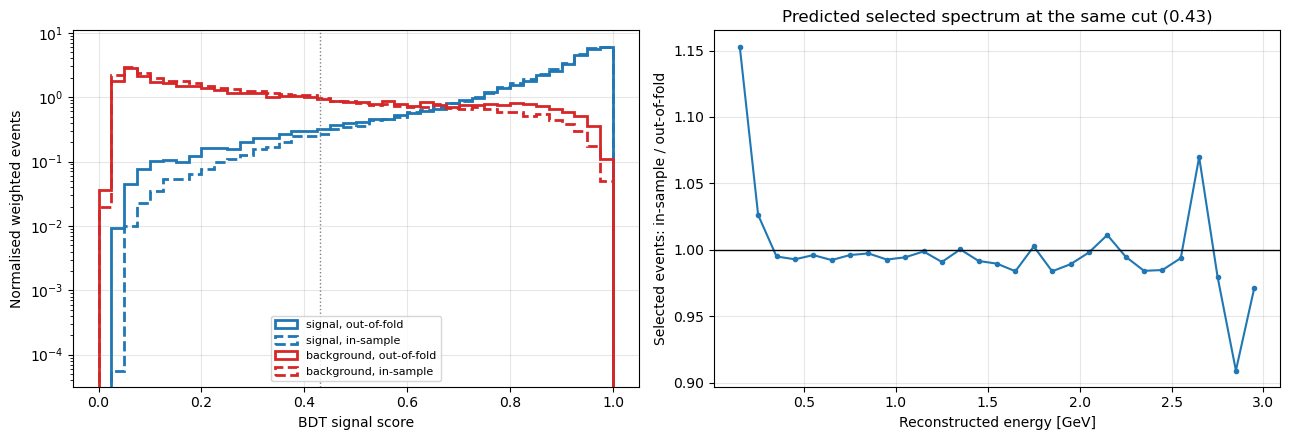

In [9]:
in_sample = in_sample_scores(main, ALL)   # each event scored by a fold model that trained on it
CUT_in = best_cut(in_sample, ALL)    # the threshold an analysis without k-fold would have chosen

auc_oof = roc_auc_score(y_all, oof_main, sample_weight=w_all)
auc_in = roc_auc_score(y_all, in_sample, sample_weight=w_all)
print(f"AUC: out-of-fold {auc_oof:.4f} | in-sample {auc_in:.4f} (in-sample is optimistic by {auc_in - auc_oof:+.4f})")

oof_m, oof_e = at_cut(oof_main, ALL, CUT), boot_se(oof_main, ALL, CUT)
in_m = at_cut(in_sample, ALL, CUT)
in_own = at_cut(in_sample, ALL, CUT_in)
table = pd.DataFrame({
    f"out-of-fold (cut {CUT:.2f})": {k: f"{v:.4f} ± {oof_e[k]:.4f}" for k, v in oof_m.items()},
    f"in-sample, same cut": {k: f"{v:.4f}" for k, v in in_m.items()},
    "bias (in-sample − out-of-fold)": {k: f"{in_m[k] - oof_m[k]:+.4f}" for k in oof_m},
    f"in-sample, its own cut ({CUT_in:.2f})": {k: f"{v:.4f}" for k, v in in_own.items()},
})
display(table)
print("Relative bias in the predicted number of selected events at the same cut: "
      f"{in_m['selected fraction'] / oof_m['selected fraction'] - 1:+.2%}")

# Where the bias appears: score distributions, and the predicted selected energy spectrum
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(15, 6))
bins = np.linspace(0, 1, 41)
for sig, name, col in [(1, "Signal", "tab:blue"), (0, "Background", "tab:red")]:
    m = y_all == sig
    ax1.hist(oof_main[m], bins=bins, weights=w_all[m], density=True, histtype="step", lw=2, color=col,
             label=f"{name}, out-of-fold")
    ax1.hist(in_sample[m], bins=bins, weights=w_all[m], density=True, histtype="step", lw=2, ls="--", color=col,
             label=f"{name}, in-sample")
ax1.axvline(CUT, color="grey", ls=":", lw=2, label=f"Cut ({CUT:.2f})")
ax1.set_yscale("log")
ax1.set_xlabel("BDT signal score")
ax1.set_ylabel("Normalised weighted events")
ax1.set_title("Score distributions")
ax1.set_ylim(top=ax1.get_ylim()[1] * 300)   # headroom above the curves for the legend
ax1.legend(loc="upper center", ncol=2, fontsize=13, handlelength=1.5, columnspacing=1)

ebins = np.linspace(0, 3, 31)
ecent = (ebins[:-1] + ebins[1:]) / 2
h_oof, _ = np.histogram(E_all[oof_main > CUT], bins=ebins, weights=w_all[oof_main > CUT])
h_in, _ = np.histogram(E_all[in_sample > CUT], bins=ebins, weights=w_all[in_sample > CUT])
ax2.plot(ecent, np.divide(h_in, h_oof, out=np.full_like(h_oof, np.nan), where=h_oof > 0), "o-", ms=6)
ax2.axhline(1, color="black", lw=1)
ax2.set_xlabel("Reconstructed energy [GeV]")
ax2.set_ylabel("Selected events,\nin-sample / out-of-fold")
ax2.set_title(f"Predicted spectrum at the same cut ({CUT:.2f})")
for ax in (ax1, ax2):
    ax.grid(alpha=0.3)
plt.tight_layout()
plt.show()

Job 2: are the out-of-fold efficiencies correct? (closure test)

Set aside 20% of the simulation (test set B) before anything else, run the full nested k-fold on the other 80% (A), including its own hyperparameter search, and choose the threshold from A's out-of-fold scores as the analysis would. Then compare A's out-of-fold efficiencies with B's, where B is scored like real data and is genuinely unseen: no choice at any stage (settings, tree counts, trees, threshold) used it. Task_2_corrected scores real data with one randomly chosen fold model per event, so that is the main comparison; the 5-model average and the single models are shown too. Agreement within the uncertainties means the out-of-fold scores are unbiased. Runs its own 5 × 40-trial search.

In [10]:
splitter = StratifiedGroupKFold(n_splits=5, shuffle=True, random_state=3)   # a split unrelated to the others
rows_A, rows_B = next(splitter.split(X, y, groups_all))
print(f"A: {len(rows_A)} events (nested k-fold), B: {len(rows_B)} events (untouched)")
kA = run_kfold(rows_A)            # tunes, trains and scores using A only
cut_A = best_cut(kA["oof"], rows_A)

XB = X.iloc[rows_B]
B_single = np.array([m.predict_proba(XB)[:, 1] for m in kA["models"]])   # each A-model on B
pick = np.random.default_rng(1).integers(0, K, len(rows_B))
B_rand = B_single[pick, np.arange(len(rows_B))]                         # one random model per event, as real data
B_avg = B_single.mean(axis=0)                                            # 5-model average, for comparison

mA, eA = at_cut(kA["oof"], rows_A, cut_A), boot_se(kA["oof"], rows_A, cut_A)
mR, eR = at_cut(B_rand, rows_B, cut_A), boot_se(B_rand, rows_B, cut_A)
mV, eV = at_cut(B_avg, rows_B, cut_A), boot_se(B_avg, rows_B, cut_A)
single = pd.DataFrame([at_cut(s, rows_B, cut_A) for s in B_single])
pull = lambda m, e: {q: f"{(mA[q] - m[q]) / np.hypot(eA[q], e[q]):+.1f}σ" for q in mA}
closure = pd.DataFrame({
    "A out-of-fold": {q: f"{v:.4f} ± {eA[q]:.4f}" for q, v in mA.items()},
    "B, one random model": {q: f"{v:.4f} ± {eR[q]:.4f}" for q, v in mR.items()},
    "pull (A vs random)": pull(mR, eR),
    "B, 5-model average": {q: f"{v:.4f} ± {eV[q]:.4f}" for q, v in mV.items()},
    "pull (A vs average)": pull(mV, eV),
    "B, single models (mean ± spread)": {q: f"{single[q].mean():.4f} ± {single[q].std():.4f}" for q in mA},
})
print(f"Threshold chosen on A: {cut_A:.2f}")
display(closure)

wB = w_all[rows_B]
auc_B = lambda s: roc_auc_score(y_all[rows_B], s, sample_weight=wB)
print(f"AUC: A out-of-fold {roc_auc_score(y_all[rows_A], kA['oof'], sample_weight=w_all[rows_A]):.4f} | "
      f"B one random model {auc_B(B_rand):.4f} | B 5-model average {auc_B(B_avg):.4f} | "
      f"B single models {np.mean([auc_B(s) for s in B_single]):.4f}")
print("Pulls within about ±2σ mean the out-of-fold efficiencies are unbiased.")

A: 76598 events (k-fold), B: 19150 events (untouched)
  fold 0: best 934 trees -> using 351
  fold 1: best 801 trees -> using 308
  fold 2: best 1070 trees -> using 330
  fold 3: best 969 trees -> using 309
  fold 4: best 1612 trees -> using 434
Threshold chosen on A: 0.40


,A out-of-fold,"B, 5-model average",difference (A − B),pull,"B, single models (mean ± spread)"
signal efficiency,0.9445 ± 0.0011,0.9485 ± 0.0021,-0.0040 ± 0.0024,-1.7σ,0.9476 ± 0.0016
Cosmic mis-ID kept,0.4044 ± 0.0070,0.4027 ± 0.0136,+0.0016 ± 0.0153,+0.1σ,0.4025 ± 0.0080
Out of fiducial vol. kept,0.6549 ± 0.0106,0.6663 ± 0.0225,-0.0114 ± 0.0249,-0.5σ,0.6668 ± 0.0224
EXT (beam off) kept,0.3258 ± 0.0048,0.3195 ± 0.0093,+0.0063 ± 0.0105,+0.6σ,0.3201 ± 0.0061
nu NC kept,0.8674 ± 0.0058,0.8838 ± 0.0106,-0.0165 ± 0.0121,-1.4σ,0.8768 ± 0.0040
purity,0.8196 ± 0.0018,0.8195 ± 0.0034,+0.0001 ± 0.0038,+0.0σ,0.8196 ± 0.0022
selected fraction,0.7882 ± 0.0018,0.7906 ± 0.0033,-0.0024 ± 0.0037,-0.6σ,0.7898 ± 0.0031


AUC: A out-of-fold 0.8850 | B 5-model average 0.8896 | B single models 0.8884
Pulls within about ±2σ mean the out-of-fold efficiencies are unbiased.


Job 3: is it stable?

How much the 5 fold models of the main k-fold differ: each model's AUC and efficiencies on the fold it never saw, their tree counts, and how much they disagree when scoring the same real events (which is what happens to the data). An event whose pass/fail depends on which model scores it is sensitive to the training randomness.

,trees,AUC,train loss,held-out loss,signal efficiency,Cosmic mis-ID kept,Out of fiducial vol. kept,EXT (beam off) kept,nu NC kept,purity,selected fraction
fold,,,,,,,,,,,
0,369,0.8877,0.3268,0.3850,0.9419,0.3729,0.6174,0.2934,0.8664,0.8273,0.7763
1,369,0.8905,0.3290,0.3793,0.9403,0.3796,0.6433,0.2895,0.8462,0.8291,0.7771
2,374,0.8833,0.3249,0.3935,0.9318,0.3614,0.5915,0.2879,0.8421,0.8258,0.7644
3,458,0.8905,0.3159,0.3786,0.9302,0.3717,0.5664,0.2707,0.8430,0.8361,0.7633
4,524,0.8868,0.3055,0.3819,0.9277,0.3589,0.5642,0.2688,0.8360,0.8388,0.7611


,mean,spread (std),relative spread
trees,418.8000,69.9478,0.1670
AUC,0.8878,0.0030,0.0034
train loss,0.3204,0.0097,0.0303
held-out loss,0.3837,0.0060,0.0157
signal efficiency,0.9344,0.0063,0.0068
Cosmic mis-ID kept,0.3689,0.0086,0.0233
Out of fiducial vol. kept,0.5965,0.0339,0.0569
EXT (beam off) kept,0.2820,0.0114,0.0405
nu NC kept,0.8468,0.0116,0.0137
purity,0.8314,0.0057,0.0069


Real data: per-event spread of the 5 models' scores: median 0.0149, 90th percentile 0.0406
Events whose pass/fail depends on which model scores them: 5.91% (fraction passing: single models [0.7742 0.7773 0.7693 0.7685 0.7655], 5-model average 0.7721)


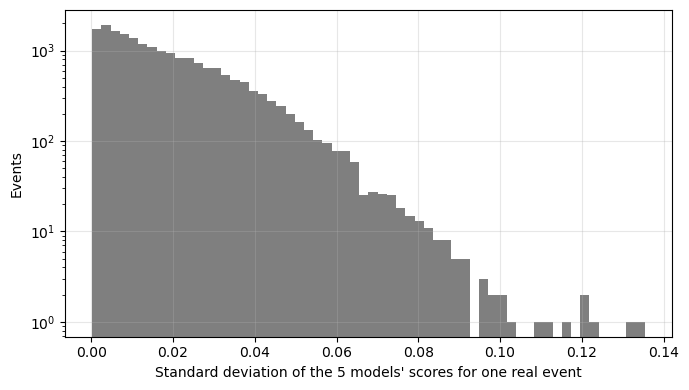

In [11]:
rows = []
for k in range(5):
    m = main["fold"] == k
    r = at_cut(oof_main[m], ALL[m], CUT)
    rows.append({"fold": k, "trees": main["trees"][k],
                 "AUC": roc_auc_score(y_all[m], oof_main[m], sample_weight=w_all[m]),
                 "train loss": main["train loss"][k], "held-out loss": main["held-out loss"][k], **r})
per_fold = pd.DataFrame(rows).set_index("fold")
summary = pd.DataFrame({"mean": per_fold.mean(), "spread (std)": per_fold.std(),
                        "relative spread": per_fold.std() / per_fold.mean().abs()})
display(per_fold.round(4))
display(summary.round(4))

# The 5 models on the same real events
Xd = data_pre[features].replace([np.inf, -np.inf], np.nan)
data_scores = np.array([m.predict_proba(Xd)[:, 1] for m in main["models"]])
spread = data_scores.std(axis=0)
passes = data_scores > CUT
undecided = passes.any(axis=0) & ~passes.all(axis=0)     # passes for some models but not others
avg_pass = data_scores.mean(axis=0) > CUT
print(f"Real data: per-event spread of the 5 models' scores: median {np.median(spread):.4f}, "
      f"90th percentile {np.quantile(spread, 0.9):.4f}")
rand_pass = passes[np.random.default_rng(1).integers(0, K, passes.shape[1]), np.arange(passes.shape[1])]   # as Task_2_corrected
print(f"Events whose pass/fail depends on which model scores them: {undecided.mean():.2%} "
      f"(fraction passing: single models {passes.mean(axis=1).round(4)}, one random model per event "
      f"{rand_pass.mean():.4f}, 5-model average {avg_pass.mean():.4f})")

fig, ax = plt.subplots(figsize=(9, 5.5))
ax.hist(spread, bins=60, color="tab:grey")
ax.set_yscale("log")
ax.set_xlabel("Std. dev. of the 5 models' scores (per real event)")
ax.set_ylabel("Real events")
ax.set_title("How much the 5 fold models disagree")
ax.grid(alpha=0.3)
plt.tight_layout()
plt.show()

Optional: is the 1-SE tree rule worth it?

Runs the nested k-fold again with `SE_SCALE = 0`: every fold's Optuna search is re-run for the minimum-loss tree count (the search and the final models both use it). Compares it with the 1-SE version: separation (out-of-fold AUC), overfitting (gap between each model's training and held-out loss), and the in-sample bias. Runs its own 5 × 40-trial search.

In [12]:
min_loss = run_kfold(ALL, se_scale=0.0)       # re-tunes every fold for the minimum-loss tree count
in_min = in_sample_scores(min_loss, ALL)

rows = []
for label, res, ins in [("1-SE rule (SE_SCALE = 1)", main, in_sample), ("minimum loss (SE_SCALE = 0)", min_loss, in_min)]:
    cut = best_cut(res["oof"], ALL)
    o, i = at_cut(res["oof"], ALL, cut), at_cut(ins, ALL, cut)
    rows.append({"tree rule": label, "mean trees": np.mean(res["trees"]),
                 "out-of-fold AUC": roc_auc_score(y_all, res["oof"], sample_weight=w_all),
                 "train - held-out loss gap": np.mean(res["held-out loss"]) - np.mean(res["train loss"]),
                 "signal efficiency": o["signal efficiency"], "purity": o["purity"],
                 "in-sample bias, signal eff": i["signal efficiency"] - o["signal efficiency"],
                 "in-sample bias, purity": i["purity"] - o["purity"]})
display(pd.DataFrame(rows).set_index("tree rule").round(4))

  fold 0: best 1010 trees -> using 1010
  fold 1: best 1097 trees -> using 1097
  fold 2: best 964 trees -> using 964
  fold 3: best 1133 trees -> using 1133
  fold 4: best 1257 trees -> using 1257


,mean trees,out-of-fold AUC,train - held-out loss gap,signal efficiency,purity,"in-sample bias, signal eff","in-sample bias, purity"
tree rule,,,,,,,
1-SE rule (SE_SCALE = 1),418.8,0.8877,0.0632,0.9344,0.8314,0.0223,0.0235
minimum loss (SE_SCALE = 0),1092.2,0.8910,0.1225,0.9412,0.8298,0.0376,0.0451


Results and interpretation

*From the run saved on 26 Oct 2026, **before this notebook was changed to the nested search** (Optuna inside every fold with the 1-SE tree count in its objective, a 20% inner validation set, in-sample scores from the fold models, real data scored by one random fold model as in Task_2_corrected). The descriptions and numbers below refer to that earlier version: one set of hyperparameters for all folds (tuned on a single 80:20 split on 21 Oct, with the old feature list), a 10% early-stopping set, and a separate model trained on all events for Job 1. Re-run the notebook and rewrite this cell before quoting anything.*

**Why the k-fold is needed here**

The simulation does two jobs: it trains the BDT, and the selected simulated events *are* the prediction fitted to the data (the predicted signal and background spectrum). Real data is always scored honestly, because no model has seen it. The simulation must be scored honestly too, or the prediction describes a better selection than the one actually applied to the data, and the fit is biased.

- Each simulated event is scored by the one model that did not train on it (the model whose held-out 20% it was in). The five held-out folds together cover all of the simulation, so every event gets exactly one honest score.
- "Out-of-fold" metrics are computed once on these pooled scores, not averaged over folds. The two agree: AUC 0.8876 pooled vs 0.8877 fold mean.
- Real data is scored by the **average of all five models**, since none of them trained on it.
- Within each fold, the 80% is split again: 72% of events train the trees, 8% (10% of the 80%) choose the tree count (early stopping + 1-SE rule). The held-out 20% is never used for any decision.

Overtraining itself is not the problem; using a model on its own training events is. The k-fold guarantees that never happens, so any amount of overtraining is safe as long as the out-of-fold performance is good (see the 1-SE comparison below).

**Job 1: the k-fold removes a large bias**

One model trained on all the simulation, scoring its own training events ("in-sample"), vs the out-of-fold scores, at the same cut (0.41):

| | Out-of-fold | In-sample | Bias | Bias / bootstrap SE |
|---|---|---|---|---|
| AUC | 0.8876 | 0.9176 | +0.030 | |
| Signal efficiency | 0.9396 | 0.9569 | +1.7 pts | 16σ |
| Purity | 0.8265 | 0.8440 | +1.75 pts | 12σ |
| OOFV kept | 0.619 | 0.529 | −9.0 pts (−14% relative) | 8σ |
| EXT kept | 0.301 | 0.256 | −4.5 pts (−15% relative) | 11σ |
| Cosmic kept | 0.383 | 0.346 | −3.7 pts (−10% relative) | 6σ |
| NC kept | 0.855 | 0.842 | −1.3 pts (−1.5% relative) | 3σ |
| Selected fraction | 0.7773 | 0.7752 | −0.27% relative | |

- The bias is far beyond statistical noise, and 2–3 times larger than in the quick test (+0.018 AUC), where trees were capped at 300.
- The errors cancel in the total but not in the composition: the selected fraction moves by only 0.27%, while signal is overstated and every background understated. A check of the total alone would never catch this.
- An analysis without the k-fold would also choose a different threshold (0.46 instead of 0.41) and quote purity 0.859, but the in-sample scores already overstate purity by 1.75 points at the same cut.
- **Energy shape (right-hand plot):** the in-sample/out-of-fold ratio is flat within about 1% from 0.3 to 2.5 GeV, but **4–5% high below 0.3 GeV**. Low-energy signal events score near the cut, so overfitting pushes them over it. This is the steep-efficiency region that can mimic an oscillation dip, and 4–5% is the size of the smallest effects the fit is sensitive to (a 4% dip at Δm² = 3 eV², sin²2θ = 0.05). Above 2.5 GeV the ratio is low-statistics noise.

**Job 2: closure test passes**

K-fold on 80% of the simulation (A), threshold chosen on A's out-of-fold scores (0.43), then applied to the untouched 20% (B) scored like real data (5-model average):

| | A out-of-fold | B, 5-model average | Pull |
|---|---|---|---|
| Signal efficiency | 0.9332 ± 0.0012 | 0.9368 ± 0.0023 | −1.4σ |
| Cosmic kept | 0.373 ± 0.007 | 0.372 ± 0.014 | +0.1σ |
| OOFV kept | 0.613 ± 0.012 | 0.632 ± 0.023 | −0.7σ |
| EXT kept | 0.291 ± 0.005 | 0.287 ± 0.009 | +0.5σ |
| NC kept | 0.844 ± 0.006 | 0.864 ± 0.012 | −1.5σ |
| Purity | 0.8289 ± 0.0018 | 0.8281 ± 0.0034 | +0.2σ |
| Selected fraction | 0.7700 ± 0.0018 | 0.7727 ± 0.0033 | −0.7σ |

- Every pull is within ±1.5σ (the quick test had signal efficiency at a borderline −1.9σ), so the out-of-fold efficiencies correctly predict the efficiencies on unseen events, which is what real data is.
- The 5-model average scores B slightly better than single models: AUC 0.8891 vs 0.8880, selected fraction 0.7727 vs 0.7715 (+0.12%). So data (averaged) and the prediction (single out-of-fold models) are not exactly the same selection, but the difference is negligible next to the 8% normalisation offset and the 15% systematic.
- B's AUC (0.8891) is 0.0045 above A's out-of-fold AUC (0.8846), within about 1.5 times the per-fold AUC spread; the efficiencies at the cut, which are what the fit uses, agree.

**Job 3: the five models are stable**

| | Mean | Spread (std) | Relative spread |
|---|---|---|---|
| Trees (1-SE) | 525 | 58 | 11% |
| AUC | 0.8877 | 0.0030 | 0.3% |
| Signal efficiency | 0.9396 | 0.0050 | 0.5% |
| Purity | 0.8265 | 0.0051 | 0.6% |
| OOFV kept | 0.620 | 0.033 | 5.3% |
| Train / held-out loss | 0.333 / 0.384 | | |

- Most spreads are what each fold's event count alone would give (bootstrap SE × √5). OOFV's 5% is mostly statistics, since it is a small category.
- Signal efficiency varies about twice as much as statistics would give (0.005 vs ≈0.0025), and drifts steadily from 0.946 (fold 0) to 0.935 (fold 4) while purity rises: each model sits at a slightly different working point at the fixed 0.41 cut.
- **Real data:** single-model pass fractions range from 0.7745 to 0.7843 (5-model average 0.7808). The median per-event spread of the five scores is 0.013 (90th percentile 0.038), and **5.6% of events pass or fail depending on which model scores them**, mostly events near the cut (the spread histogram has a smooth tail, no outliers). This is training randomness, not bias, and averaging the five models reduces it.
- Mild overfitting remains even with the 1-SE rule: held-out loss is 0.05 above training loss.

**Optional: the 1-SE rule costs a little performance**

| | Mean trees | Out-of-fold AUC | Signal eff. | Purity | Loss gap | In-sample bias (signal eff.) |
|---|---|---|---|---|---|---|
| 1-SE rule | 525 | 0.8876 | 0.9396 | 0.8265 | 0.051 | +1.7 pts |
| Minimum loss | 1394 | **0.8912** | 0.9403 | **0.8302** | 0.107 | +3.4 pts |

- The minimum-loss models overtrain twice as much but are genuinely better on events they never saw: +0.0036 AUC and +0.4 points of purity at the same signal efficiency.
- The 1-SE rule's smaller loss gap and in-sample bias don't matter here, because the k-fold removes the in-sample bias anyway.
- The rule is aggressive because the SE comes from the small 8% early-stopping set (≈0.007): it removes 60% of the trees.
- The remaining argument for 1-SE is robustness: 1,400 trees could learn simulation-specific detail that real data doesn't share. Test this with the data-vs-simulation pass-fraction check at `SE_SCALE = 0`.
- In practice the gain is small: sensitivity is limited by the 15% systematic, so 0.4 points of purity barely moves the contour. Switching to `SE_SCALE = 0` (or 0.5) is defensible now that the k-fold is validated; either way, this table is the justification.

**Summary for the report**

1. **Job 1** is the headline: without the k-fold, the prediction would overstate signal efficiency by 1.7 points, understate the main backgrounds by 10–15% relative and distort the spectrum below 0.3 GeV by 4–5%, while the total count looks right.
2. **Job 2:** the out-of-fold efficiencies are unbiased (all pulls within ±1.5σ on an untouched 20%).
3. **Job 3:** the five models agree to 0.3% in AUC; 5.6% of real events change pass/fail between models, which the 5-model average reduces. Data (averaged) vs prediction (single models) differ by about 0.1% in selected fraction.
4. **Known minor optimisms:** the threshold is chosen on the same out-of-fold scores used for the prediction; data uses a 5-model average while the simulation uses single models (+0.1%).